Spectrum of Cesium-137

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from lmfit import models

In [8]:
h_Cs = 243.17576721634862 
h_Na_1 = 197.22530992597498
h_Na_2 = 499.298182758717

E_Cs = 661.638 #keV
E_Na_1 = 511.006 #keV
E_Na_2 = 1274.511


h_Cs_err = 0.1595702654960676
h_Na_err_1 = 0.4509864330864726
h_Na_err_2 = 3.7916435080428266


E = [E_Cs, E_Na_1, E_Na_2]
h_err = [h_Cs_err, h_Na_err_1, h_Na_err_2]
h = [h_Cs, h_Na_1, h_Na_2]

In [9]:
h_err_array = np.array(h_err)

h_inv_err = 1 / h_err_array
h_inv_err = list(h_inv_err)

In [10]:
def linear_model(x,a,b):
    y = a*x + b
    return y

In [11]:
spectrum = models.Model(linear_model)
fit_result = spectrum.fit(E, x=h, a=1, b=-65, weights=h_inv_err)

print(fit_result.fit_report())

[[Model]]
    Model(linear_model)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 7
    # data points      = 3
    # variables        = 2
    chi-square         = 2358.58382
    reduced chi-square = 2358.58382
    Akaike info crit   = 24.0016131
    Bayesian info crit = 22.1988376
    R-squared          = 0.93118512
[[Variables]]
    a:  2.98359957 +/- 0.41095531 (13.77%) (init = 1)
    b: -65.6423766 +/- 98.2735549 (149.71%) (init = -65)
[[Correlations]] (unreported correlations are < 0.100)
    C(a, b) = -0.9972


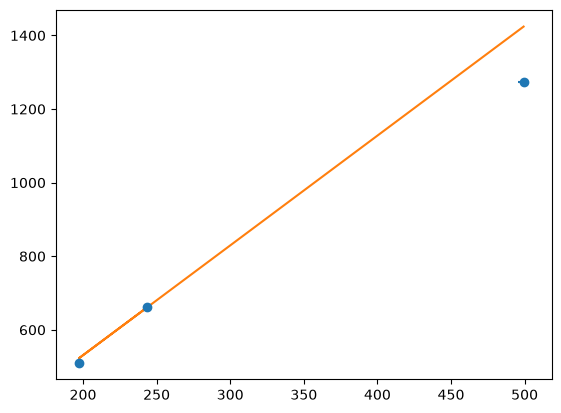

In [12]:
plt.errorbar(h,E,xerr=h_err, fmt='o')
plt.plot(h, fit_result.best_fit)
# plt.ylim(0,1000)
# plt.xlim(0, 2000)
plt.show()